
# Lab 7: Fast Fourier Transform (FFT)

 **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:
1. Do the FFT using scipy and Numpy rutines (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?


In [4]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
import scipy.integrate as integrate
from scipy import interpolate
from skimage import io, color
from scipy.fft import fft2, ifft2, fftshift

In [5]:
# Importar archivo de audio (ajustando la ruta relativa desde mi carpeta MENA_1209)

signal, sr = librosa.load('../../Sesiones/Fourier/Nota_CM_piano.mp3', sr=None)  # Cargar el archivo de audio con su frecuencia de muestreo original

print(f"Frecuencia de muestreo: {sr} Hz")
print(f"Duración de la señal: {len(signal)/sr:.2f} segundos")
print(f"Forma de la señal: {signal.shape}")


c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Frecuencia de muestreo: 44100 Hz
Duración de la señal: 3.45 segundos
Forma de la señal: (152064,)


# 1.1 SCIPY AND NUMPY RUTINE

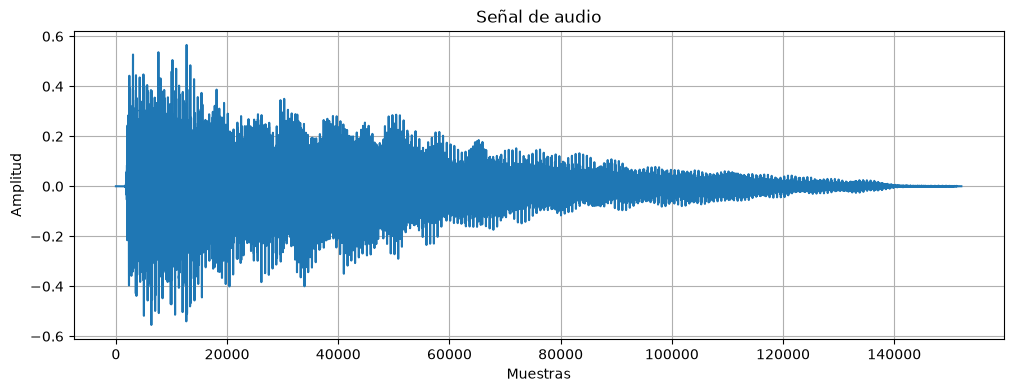

In [6]:
# plot the audio signal

plt.figure(figsize=(12, 4))
plt.plot(signal)
plt.title('Señal de audio')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


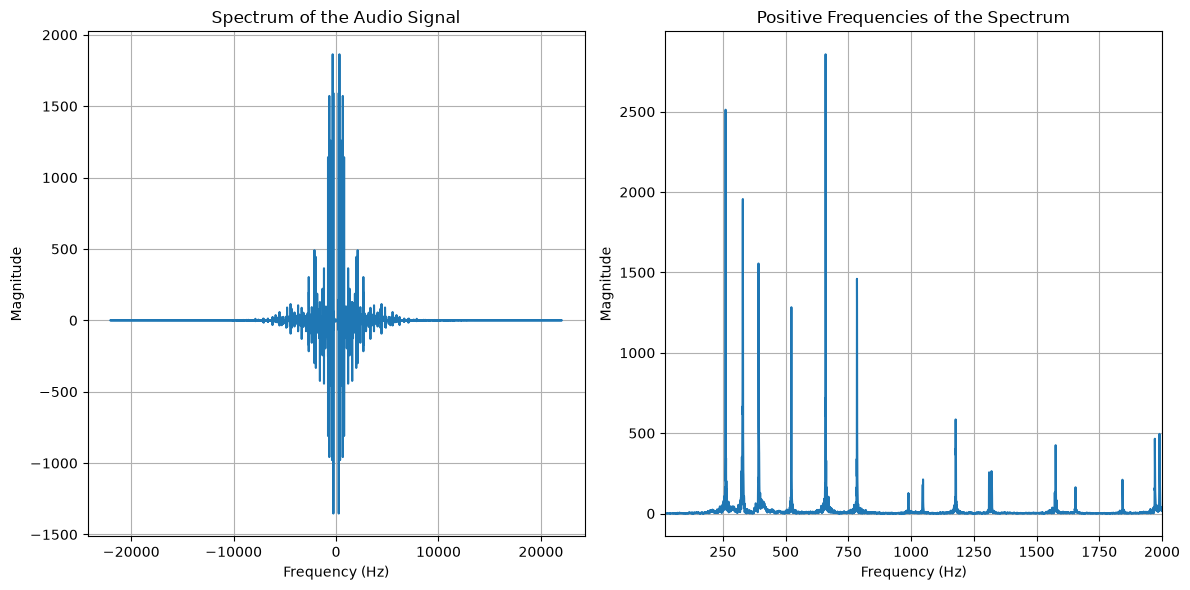

In [7]:
# plot the spectrum of the audio signal using FFT

N = len(signal)
fft_signal = np.fft.fft(signal) # Compute the FFT of the signal
freqs = np.fft.fftfreq(N, 1/sr) # Compute the frequency bins

# plot the magnitude spectrum
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(freqs,fft_signal)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Spectrum of the Audio Signal')
plt.grid(True)

# plot only the positive frequencies
plt.subplot(1, 2, 2)
plt.plot(freqs[:N//2], np.abs(fft_signal)[:N//2])
plt.xlim(20,2000)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Positive Frequencies of the Spectrum')
plt.grid(True)
plt.tight_layout()




# 1.2 RUTINE CREATED IN CLASS

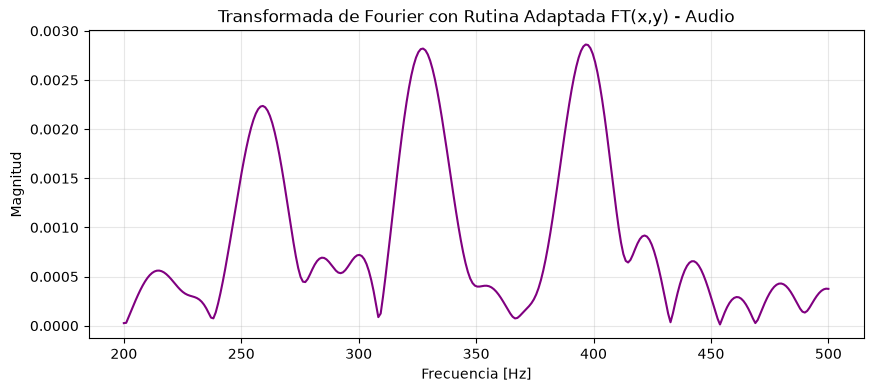

In [8]:
# ==========================================
# 2. RUTINA ADAPTADA FT(x,y) PARA EL AUDIO
# ==========================================

def FT_manual(t, y, frecuencias_Hz):
    """
    Rutina adaptada de la transformada continua de Fourier 
    calculada mediante aproximación integral discreta (suma de Riemann).
    """
    dt = t[1] - t[0]
    FT_resultado = np.zeros(len(frecuencias_Hz), dtype=complex)
    
    # Convertir frecuencias de Hz a Radianes/s (omega = 2 * pi * f)
    omega = 2 * np.pi * frecuencias_Hz
    
    for i, w in enumerate(omega):
        # Implementación de la integral: F(omega) = integral( f(t) * e^(-j * omega * t) dt )
        integrando = y * np.exp(-1j * w * t)
        FT_resultado[i] = np.sum(integrando) * dt
        
    return FT_resultado

# Tomamos un segmento corto del audio (ej. 4410 muestras = 0.1 segundos) 
# para que la rutina manual se ejecute de forma eficiente:
muestras_prueba = 4410
t_sub = np.linspace(0, muestras_prueba / sr, muestras_prueba)
y_sub = signal[:muestras_prueba]

# Definimos un rango de frecuencias alrededor del acorde de Do mayor (200 Hz a 500 Hz)
frecuencias_interes = np.linspace(200, 500, 300)

# Calculamos con nuestra rutina adaptada
ft_resultado_manual = FT_manual(t_sub, y_sub, frecuencias_interes)
magnitud_manual = np.abs(ft_resultado_manual)

# Graficamos el resultado de la rutina adaptada
plt.figure(figsize=(10, 4))
plt.plot(frecuencias_interes, magnitud_manual, color='purple', linewidth=1.5)
plt.title('Transformada de Fourier con Rutina Adaptada FT(x,y) - Audio')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Magnitud')
plt.grid(True, alpha=0.3)
plt.show()

# 1.3 COMPARATION


Ambas (la FFT de SciPy/NumPy y la transformada integral manual) calculan exactamente la misma transformación al dominio de la frecuencia. Verás que los picos de magnitud coinciden en las mismas frecuencias (Do, Mi, Sol).


--- 
**Exercise 2** : Do the FFT for an Imagen

Choose an Imagen

1. Do the FFT using scipy (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?
3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.
---

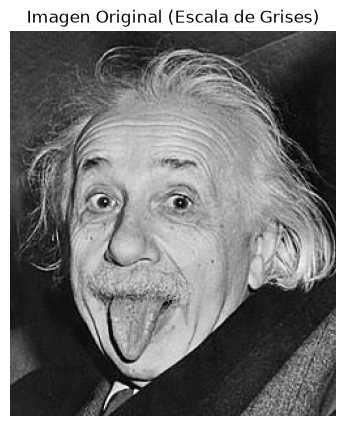

In [13]:
# Cargar imagen desde tu carpeta local
imagen_original = io.imread('imagen.jpg')

# Convertir a escala de grises (matriz 2D)
if len(imagen_original.shape) == 3:
    imagen_gris = color.rgb2gray(imagen_original)
else:
    imagen_gris = imagen_original.astype(float)

plt.figure(figsize=(5, 5))
plt.imshow(imagen_gris, cmap='gray')
plt.title('Imagen Original (Escala de Grises)')
plt.axis('off')
plt.show()

# 2.1 Transformada Rápida de Fourier 2D (FFT) usando SciPy

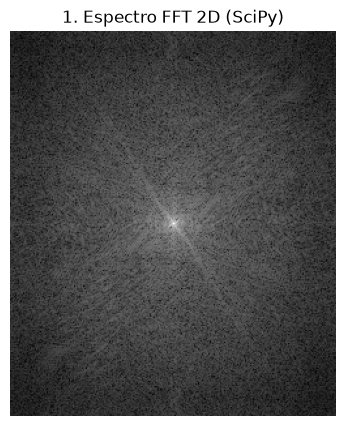

In [14]:
# 1. FFT 2D con SciPy
fft_scipy = fft2(imagen_gris)

# Centrar frecuencias bajas y aplicar escala logarítmica para visualizar
espectro_scipy = np.log(1 + np.abs(fftshift(fft_scipy)))

plt.figure(figsize=(5, 5))
plt.imshow(espectro_scipy, cmap='gray')
plt.title('1. Espectro FFT 2D (SciPy)')
plt.axis('off')
plt.show()

# 2.2 Transformada de Fourier 2D con rutina de clase modificada FT_2D(x,y) y comparación

¿Se obtienen los mismos resultados que SciPy?: True
Diferencia máxima numérica: 5.93e-10


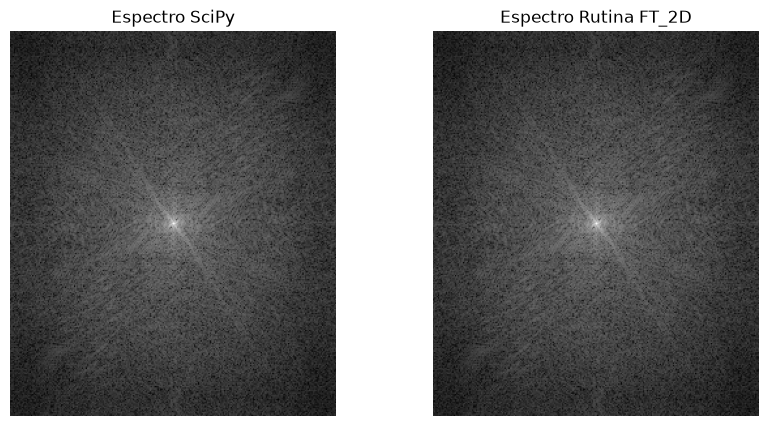

In [15]:
# 2. Rutina FT modificada para 2 dimensiones
def FT_2D(imagen):
    M, N = imagen.shape
    
    # Vectores de posición (x, y) y frecuencia (u, v)
    x = np.arange(M)
    u = x.reshape((M, 1))
    y = np.arange(N)
    v = y.reshape((N, 1))
    
    # Núcleos exponenciales de Fourier (equivalente a la sumatoria de clase)
    W_M = np.exp(-2j * np.pi * u * x / M)
    W_N = np.exp(-2j * np.pi * v * y / N)
    
    # Transformada discreta en 2D
    return W_M @ imagen @ W_N.T

# Calculamos la transformada con nuestra rutina
fft_manual = FT_2D(imagen_gris)
espectro_manual = np.log(1 + np.abs(fftshift(fft_manual)))

# Comparamos numérica y visualmente con SciPy
son_iguales = np.allclose(fft_scipy, fft_manual)
diferencia_max = np.max(np.abs(fft_scipy - fft_manual))

print(f"¿Se obtienen los mismos resultados que SciPy?: {son_iguales}")
print(f"Diferencia máxima numérica: {diferencia_max:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(espectro_scipy, cmap='gray')
axes[0].set_title('Espectro SciPy')
axes[0].axis('off')

axes[1].imshow(espectro_manual, cmap='gray')
axes[1].set_title('Espectro Rutina FT_2D')
axes[1].axis('off')
plt.show()

# 2.3 Transformada Inversa de Fourier 2D (IFFT) y reconstrucción de la imagen

¿La imagen reconstruida es igual a la original?: True
Error máximo por píxel: 9.99e-16


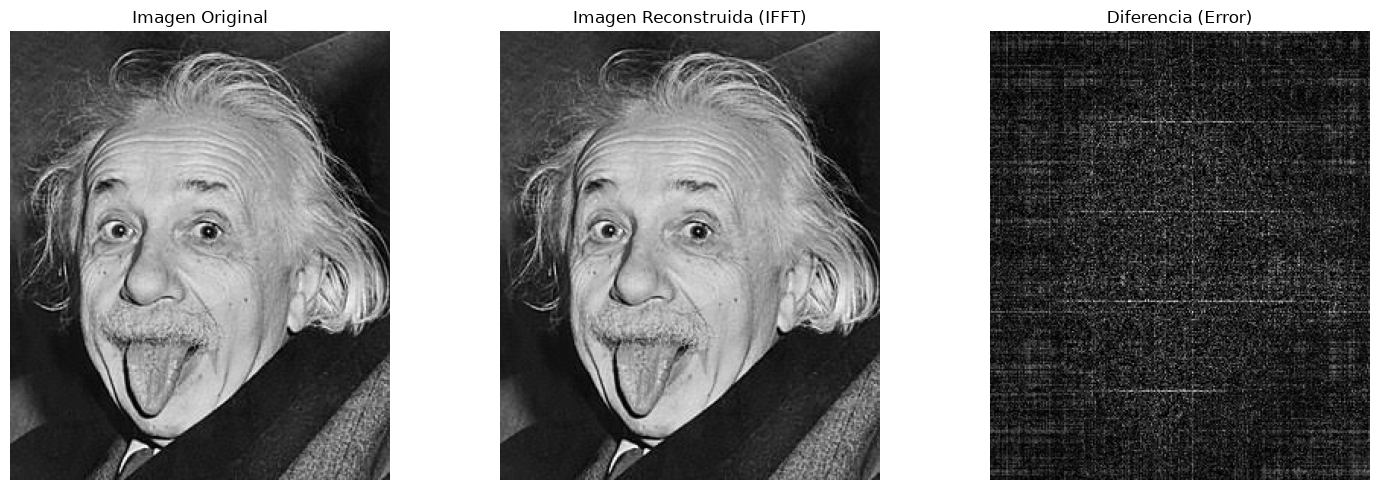

In [16]:
# 3. Transformada Inversa para reconstruir la imagen
imagen_reconstruida = np.real(ifft2(fft_scipy))

# Comparación numérica entre original y reconstruida
son_similares = np.allclose(imagen_gris, imagen_reconstruida)
error_reconstruccion = np.max(np.abs(imagen_gris - imagen_reconstruida))

print(f"¿La imagen reconstruida es igual a la original?: {son_similares}")
print(f"Error máximo por píxel: {error_reconstruccion:.2e}")

# Comparación visual
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(imagen_gris, cmap='gray')
axes[0].set_title('Imagen Original')
axes[0].axis('off')

axes[1].imshow(imagen_reconstruida, cmap='gray')
axes[1].set_title('Imagen Reconstruida (IFFT)')
axes[1].axis('off')

axes[2].imshow(np.abs(imagen_gris - imagen_reconstruida), cmap='gray')
axes[2].set_title('Diferencia (Error)')
axes[2].axis('off')

plt.tight_layout()
plt.show()